## Testing the Price Impact Simulator

1. Building/Testing a L2Book that can simulate fills for orders and price impact using L2 MBP-10 Databento orderbook.
    1. The book should be able to simulate changes to the orderbook from orders. It should simulate market orders and IOC orders. It should also have a replenishment parameter.
    2. Order's have a latency parameter
2. Explore the predictive power of OBI via markouts. (to suport it's use in an execution strategy).
3. Milestone: Simulate one-step ahead order fill simulation with latencies, price protection (IOC ordertype) and replenishment(?)
4. Final: Simulate >1 step ahead, compare chunking a parent order via zero-intelligence constant fills vs OBI-aware strategies.
    1. Compare the summed arrival cost these two strategies with the mechanical price impact of sweeping the book with a single large order. (Should be arrival cost: immediate sweep > constant fills > obi adaptive or other strategy)
    2. See how dependent the strategies are on latency, replenishment, and asset (3 stocks from lecture 8, large/small tick, large/small cap)
    3. Possibly implement limit orders?

### Part 1: Dev/Testing Simulator


In [1]:
from dotenv import load_dotenv
import sys
sys.path.insert(0, '..')
import os
import databento as db
import numpy as np
import pandas as pd
import polars as pl
from saf_lib.helpers import DataBentoMBP10Adapter
from saf_lib.simulation import *
load_dotenv()

adapter = DataBentoMBP10Adapter(api_key=os.environ["DATABENTO_API_KEY"])
raw_data = adapter.get_data(
    tickers=["BKNG", "AMZN", "DRH"],
    start_date="2026-03-25",
    end_date="2026-03-27",
    dataset="XNAS.ITCH",
    cache_only=False
)
print(f"Loaded {len(raw_data):,} ticks")
print(f"Date range: {raw_data.index.min()} to {raw_data.index.max()}")
print(f"Columns: {raw_data.columns.tolist()}")

MBP10 AMZN,BKNG,DRH: 100%|██████████| 4/4 [00:00<00:00, 6631.31step/s, parquet cache hit] 


Loaded 5,879,570 ticks
Date range: 2026-03-25 09:30:00.000285597-04:00 to 2026-03-26 15:59:59.999797966-04:00
Columns: ['ts_event', 'rtype', 'publisher_id', 'instrument_id', 'action', 'side', 'depth', 'price', 'size', 'flags', 'ts_in_delta', 'sequence', 'bid_px_00', 'ask_px_00', 'bid_sz_00', 'ask_sz_00', 'bid_ct_00', 'ask_ct_00', 'bid_px_01', 'ask_px_01', 'bid_sz_01', 'ask_sz_01', 'bid_ct_01', 'ask_ct_01', 'bid_px_02', 'ask_px_02', 'bid_sz_02', 'ask_sz_02', 'bid_ct_02', 'ask_ct_02', 'bid_px_03', 'ask_px_03', 'bid_sz_03', 'ask_sz_03', 'bid_ct_03', 'ask_ct_03', 'bid_px_04', 'ask_px_04', 'bid_sz_04', 'ask_sz_04', 'bid_ct_04', 'ask_ct_04', 'bid_px_05', 'ask_px_05', 'bid_sz_05', 'ask_sz_05', 'bid_ct_05', 'ask_ct_05', 'bid_px_06', 'ask_px_06', 'bid_sz_06', 'ask_sz_06', 'bid_ct_06', 'ask_ct_06', 'bid_px_07', 'ask_px_07', 'bid_sz_07', 'ask_sz_07', 'bid_ct_07', 'ask_ct_07', 'bid_px_08', 'ask_px_08', 'bid_sz_08', 'ask_sz_08', 'bid_ct_08', 'ask_ct_08', 'bid_px_09', 'ask_px_09', 'bid_sz_09', 'ask_

In [2]:
raw_data

,ts_event,rtype,publisher_id,instrument_id,action,side,depth,price,size,flags,...,bid_ct_08,ask_ct_08,bid_px_09,ask_px_09,bid_sz_09,ask_sz_09,bid_ct_09,ask_ct_09,symbol,book_imbalance
ts_recv,,,,,,,,,,,,,,,,,,,,,
2026-03-25 09:30:00.000285597-04:00,2026-03-25 13:30:00.000121575+00:00,10,2,853,T,N,0,211.66,1,128,...,1,1,211.20,212.25,215,48,3,1,AMZN,0.109489
2026-03-25 09:30:00.001169571-04:00,2026-03-25 13:30:00.001006683+00:00,10,2,853,A,B,0,211.62,100,128,...,1,1,211.20,212.25,215,48,3,1,AMZN,0.153617
2026-03-25 09:30:00.001322597-04:00,2026-03-25 13:30:00.001156040+00:00,10,2,853,T,N,0,211.66,220,128,...,1,1,211.20,212.25,215,48,3,1,AMZN,0.153617
2026-03-25 09:30:00.003351400-04:00,2026-03-25 13:30:00.003182562+00:00,10,2,853,T,N,0,211.65,20,0,...,1,1,211.20,212.25,215,48,3,1,AMZN,0.153617
2026-03-25 09:30:00.003351400-04:00,2026-03-25 13:30:00.003182562+00:00,10,2,853,T,N,0,211.63,468,0,...,1,1,211.20,212.25,215,48,3,1,AMZN,0.153617
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-26 15:59:59.997515488-04:00,2026-03-26 19:59:59.997348310+00:00,10,2,4576,C,A,0,9.59,17,128,...,1,1,9.46,9.75,200,100,2,1,DRH,-0.172172
2026-03-26 15:59:59.998348-04:00,2026-03-26 19:59:59.998183024+00:00,10,2,853,A,B,0,207.53,9400,128,...,4,2,207.43,207.65,3600,1873,2,3,AMZN,0.715051
2026-03-26 15:59:59.998833176-04:00,2026-03-26 19:59:59.998663846+00:00,10,2,4576,A,A,0,9.59,100,128,...,1,1,9.46,9.75,200,100,2,1,DRH,-0.172624


In [3]:
symbol_map = {853 : "AMZN", 4576:"DRH", 2021:"BKNG"}
df = pl.from_pandas(raw_data)
# Returns an Int64 column of nanoseconds
df = df.with_columns(
    pl.col("ts_event").dt.timestamp("ns").alias("ts_event_nano")
)

cols = ["ts_event_nano", "instrument_id"] + [
    col for n in range(0, 10)
    for col in [f"bid_px_{str(n).zfill(2)}", f"ask_px_{str(n).zfill(2)}", f"bid_sz_{str(n).zfill(2)}", f"ask_sz_{str(n).zfill(2)}"]
]

df = df.select(cols)
df = df.unique(subset="ts_event_nano", keep="last").sort("ts_event_nano")
df

ts_event_nano,instrument_id,bid_px_00,ask_px_00,bid_sz_00,ask_sz_00,bid_px_01,ask_px_01,bid_sz_01,ask_sz_01,bid_px_02,ask_px_02,bid_sz_02,ask_sz_02,bid_px_03,ask_px_03,bid_sz_03,ask_sz_03,bid_px_04,ask_px_04,bid_sz_04,ask_sz_04,bid_px_05,ask_px_05,bid_sz_05,ask_sz_05,bid_px_06,ask_px_06,bid_sz_06,ask_sz_06,bid_px_07,ask_px_07,bid_sz_07,ask_sz_07,bid_px_08,ask_px_08,bid_sz_08,ask_sz_08,bid_px_09,ask_px_09,bid_sz_09,ask_sz_09
i64,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32
1774445400000121575,853,211.62,211.71,270,1,211.6,211.78,1,1,211.54,211.84,23,100,211.5,211.9,5,4,211.43,212.0,100,489,211.3,212.02,200,5,211.25,212.16,50,5,211.24,212.18,100,1,211.22,212.2,100,200,211.2,212.25,215,48
1774445400001006683,853,211.62,211.71,370,1,211.6,211.78,1,1,211.54,211.84,23,100,211.5,211.9,5,4,211.43,212.0,100,489,211.3,212.02,200,5,211.25,212.16,50,5,211.24,212.18,100,1,211.22,212.2,100,200,211.2,212.25,215,48
1774445400001156040,853,211.62,211.71,370,1,211.6,211.78,1,1,211.54,211.84,23,100,211.5,211.9,5,4,211.43,212.0,100,489,211.3,212.02,200,5,211.25,212.16,50,5,211.24,212.18,100,1,211.22,212.2,100,200,211.2,212.25,215,48
1774445400003182562,853,211.6,211.71,1,1,211.54,211.78,23,1,211.5,211.84,5,100,211.43,211.9,100,4,211.3,212.0,200,489,211.25,212.02,50,5,211.24,212.16,100,5,211.22,212.18,100,1,211.2,212.2,215,200,211.18,212.25,100,48
1774445400003232384,853,211.6,211.7,1,46,211.54,211.71,23,1,211.5,211.78,5,1,211.43,211.84,100,100,211.3,211.9,200,4,211.25,212.0,50,489,211.24,212.02,100,5,211.22,212.16,100,5,211.2,212.18,215,1,211.18,212.2,100,200
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1774555199997348310,4576,9.58,9.59,3476,26416,9.57,9.6,10955,22902,9.56,9.61,5562,26202,9.55,9.62,12900,1600,9.54,9.63,3500,1200,9.53,9.64,2600,13100,9.51,9.65,13200,11900,9.48,9.72,11700,3800,9.47,9.73,11700,100,9.46,9.75,200,100
1774555199998183024,853,207.53,207.55,9660,171,207.52,207.56,16967,1,207.5,207.58,3229,447,207.49,207.59,2767,348,207.48,207.6,63,376,207.47,207.61,4000,100,207.46,207.62,4590,70,207.45,207.63,3801,5354,207.44,207.64,5733,300,207.43,207.65,3600,1873
1774555199998663846,4576,9.58,9.59,3476,26516,9.57,9.6,10955,22902,9.56,9.61,5562,26202,9.55,9.62,12900,1600,9.54,9.63,3500,1200,9.53,9.64,2600,13100,9.51,9.65,13200,11900,9.48,9.72,11700,3800,9.47,9.73,11700,100,9.46,9.75,200,100


### zero-intelligence executors

In [4]:
def _generate_letency(mu: int = 5_000_000, sigma: int = 2_000_000) -> int:
    """
    Generate a nanosecond latency
    
    Parameters
        ----------
        mu : int
            Mean (ns)
        sigma : int
            St deviation (ns)

        Returns
        -------
        int
            latency integer in nanoseconds
    """
    from scipy.stats import truncnorm
    # Parameters
    lower, upper = 0, float('inf')
    a, b = (lower - mu) / sigma, (upper - mu) / sigma
    rv = truncnorm(a, b, loc=mu, scale=sigma)
    latency_ns = int(rv.rvs(1)[0])
    return latency_ns

def naive_filler(side, parent_size, ts_nano, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    result = sim.accept_mkt_order(side, parent_size, ts_nano, latency_ns)
    df_new = sim.get_book_df()
    return result, df_new

def constant_filler(side: str, parent_size: int, start_ts_ns: int, wait_ns: int, 
                 n_chunks:int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    chunk_size = int(parent_size / n_chunks)
    times = np.arange(start_ts_ns, start_ts_ns + n_chunks * wait_ns, wait_ns)
    results = []
    for t in times:
        r = sim.accept_mkt_order(side, chunk_size, t, latency_ns)
        results.append(r)
    df_new = sim.get_book_df()
    return results, df_new

def constant_ioc_filler(side: str, limit_px: float, parent_size: int, start_ts_ns: int, wait_ns: int,
                 n_chunks:int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    chunk_size = int(parent_size / n_chunks)
    times = np.arange(start_ts_ns, start_ts_ns + n_chunks * wait_ns, wait_ns)
    results = []
    for t in times:
        r = sim.accept_ioc_lmt_order(side, limit_px, chunk_size, t, latency_ns)
        results.append(r)
    df_new = sim.get_book_df()
    return results, df_new

{'vwap': 210.82838, 'fills': [(210.84, 138), (210.83, 143), (210.82, 219)], 'total_filled': 500, 'levels_swept': 2, 'executed_at_ns': 1774454789302820063, 'executed_at_idx': 1545606, 'arrival_cost': 0.026620000000008304}


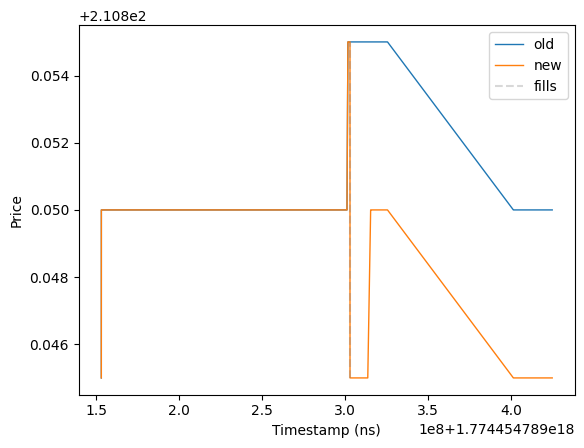

In [5]:
import matplotlib.pyplot as plt
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
PARENT_QTY = 500
SIDE="SELL"

results, new_df = naive_filler(SIDE, PARENT_QTY, TS_NANO, sim)

new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results['executed_at_idx']-20
i_end = results['executed_at_idx']+20
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines(results["executed_at_ns"], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()

[{'vwap': 212.66941999999997, 'fills': [(212.68, 256), (212.67, 430), (212.66, 314)], 'total_filled': 1000, 'levels_swept': 2, 'executed_at_ns': 1774460473106063190, 'executed_at_idx': 2145533, 'arrival_cost': 0.0205800000000238}, {'vwap': 212.61285999999998, 'fills': [(212.63, 128), (212.62, 250), (212.61, 402), (212.6, 220)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774460573090220728, 'executed_at_idx': 2155693, 'arrival_cost': 0.022140000000007376}, {'vwap': 212.77828, 'fills': [(212.79, 282), (212.78, 269), (212.77, 444), (212.76, 5)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774460673084693446, 'executed_at_idx': 2171320, 'arrival_cost': 0.02172000000001617}, {'vwap': 212.56242, 'fills': [(212.59, 8), (212.58, 151), (212.57, 244), (212.56, 269), (212.55, 328)], 'total_filled': 1000, 'levels_swept': 4, 'executed_at_ns': 1774460772937344423, 'executed_at_idx': 2182216, 'arrival_cost': 0.032579999999995835}, {'vwap': 212.39308, 'fills': [(212.4,

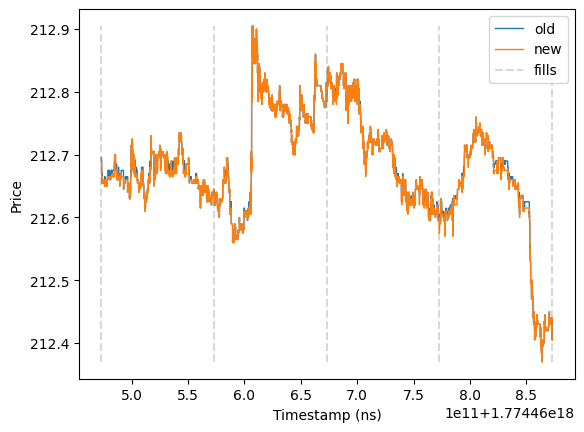

In [6]:
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
PARENT_QTY = 5000
SIDE="SELL"
WAIT_NS = 10 * 10e9 # 10s

results, new_df = constant_filler(SIDE, PARENT_QTY, TS_NANO, wait_ns=WAIT_NS, n_chunks=5, sim=sim)
new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results[0]['executed_at_idx']-10
i_end = results[-1]['executed_at_idx']+10
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines([r["executed_at_ns"] for r in results], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()

[{'vwap': 212.10073770491803, 'fills': [(212.12, 66), (212.11, 166), (212.1, 256), (212.09, 244)], 'total_filled': 732, 'levels_swept': 4, 'executed_at_ns': 1774539834764627267, 'executed_at_idx': 4235211, 'arrival_cost': 0.02926229508196343}, {'vwap': 212.23623999999998, 'fills': [(212.25, 246), (212.24, 270), (212.23, 346), (212.22, 138)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774539934650359344, 'executed_at_idx': 4242294, 'arrival_cost': 0.028760000000005448}, {'vwap': 212.13506, 'fills': [(212.15, 178), (212.14, 349), (212.13, 274), (212.12, 199)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774540034765549246, 'executed_at_idx': 4264333, 'arrival_cost': 0.029940000000010514}, {'vwap': 0.0, 'fills': [], 'total_filled': 0, 'levels_swept': 0, 'executed_at_ns': 1774540134714708879, 'executed_at_idx': 4279119, 'arrival_cost': None}, {'vwap': 0.0, 'fills': [], 'total_filled': 0, 'levels_swept': 0, 'executed_at_ns': 1774540234599581782, 'executed_at

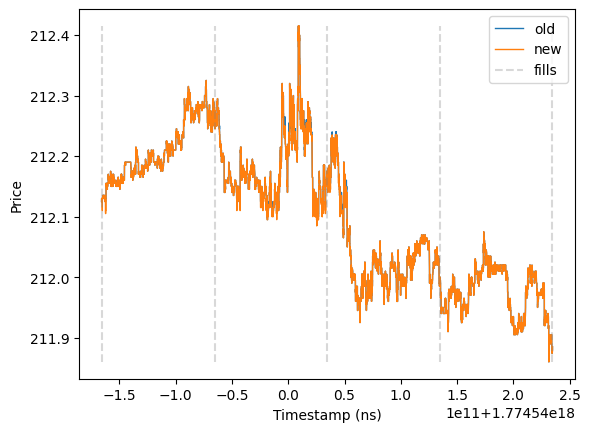

Total Filled: 2732 of 5000


In [7]:
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
LIMIT_PX = old_df.filter(pl.col("ts_event_nano") == TS_NANO)["bid_px_03"][0]
PARENT_QTY = 5000
SIDE="SELL"
WAIT_NS = 10 * 10e9 # 10s

results, new_df = constant_ioc_filler(SIDE, LIMIT_PX, PARENT_QTY, TS_NANO, wait_ns=WAIT_NS, n_chunks=5, sim=sim)

new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results[0]['executed_at_idx']-10
i_end = results[-1]['executed_at_idx']+10
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines([r["executed_at_ns"] for r in results], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()


print(f"Total Filled: {sum(r["total_filled"] for r in results)} of {PARENT_QTY}")

### Now the intelligent executors

In [8]:
def obi_adaptive_filler(df: pl.DataFrame, side: str, limit_px: float, parent_size: int, max_size: int, threshold:float,
                        start_ts_ns: int, horizon: int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    df = df.with_row_index("idx")
    results = []
    remaining = parent_size
    start_idx = df.filter(pl.col("ts_event_nano") == start_ts_ns)["idx"][0]

    obi = ((df["bid_sz_00"] - df["ask_sz_00"]) / (df["bid_sz_00"] + df["ask_sz_00"]))[start_idx:]
    for row, idx in zip(df[start_idx:].iter_rows(named=True), range(len(df[start_idx:]))):
        ts_nano = row["ts_event_nano"]
        size = min(max_size * obi[idx], remaining)
        if obi[idx] > threshold and side == "BUY":
            r = sim.accept_ioc_lmt_order(side, limit_px, size, ts_nano, latency_ns)
            remaining -= r["total_filled"]
            results.append(r)
        if obi[idx] < threshold and side == "SELL":
            r = sim.accept_ioc_lmt_order(side, limit_px, size, ts_nano, latency_ns)
            remaining -= r["total_filled"]
            results.append(r)
        if remaining == 0:
            break
        if ts_nano > start_ts_ns + horizon:
            break

        #df = sim.get_book_df()
    
    return results, df

In [9]:
# def obi_adaptive_filler(df: pl.DataFrame, side: str, limit_px: float, parent_size: int, max_size: int, threshold: float,
#                         start_ts_ns: int, horizon: int, sim: ExecutionSimulator):
#     latency_ns = _generate_letency()

#     # Vectorized: slice to window, compute OBI + size, filter by threshold
#     candidates = (
#         df.filter(
#             (pl.col("ts_event_nano") >= start_ts_ns) &
#             (pl.col("ts_event_nano") <= start_ts_ns + horizon)
#         )
#         .with_columns(
#             pl.col("bid_sz_00").fill_null(0).fill_nan(0).alias("bid_sz_00"),
#             pl.col("ask_sz_00").fill_null(0).fill_nan(0).alias("ask_sz_00"),
#         )
#         .with_columns(
#             ((pl.col("bid_sz_00") - pl.col("ask_sz_00")) / (pl.col("bid_sz_00") + pl.col("ask_sz_00"))).alias("obi")
#         )
#         .with_columns(
#             (pl.col("obi") * max_size).clip(0, None).cast(pl.Int64).alias("order_size")
#         )
#         .filter(
#             pl.when(pl.lit(side == "BUY"))
#             .then(pl.col("obi") > threshold)
#             .otherwise(pl.col("obi") < threshold)
#         )
#     )

#     # Sequential loop only over candidate rows (small fraction of original)
#     results = []
#     remaining = parent_size
#     for row in candidates.iter_rows(named=True):
#         size = min(row["order_size"], remaining)
#         if size <= 0:
#             continue
#         r = sim.accept_ioc_lmt_order(side, limit_px, size, row["ts_event_nano"], latency_ns)
#         remaining -= r["total_filled"]
#         results.append(r)
#         if remaining <= 0:
#             break

#     return results, sim.get_book_df()


In [10]:
def obi_adaptive_filler(df: pl.DataFrame, side: str, parent_size: int, max_size: int, threshold: float,
                        start_ts_ns: int, horizon: int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    init_ts_ns = start_ts_ns
    results = []
    remaining = parent_size
    book_df = df
    while remaining > 0 or start_ts_ns < horizon + init_ts_ns:
        # Vectorized: slice to window, recompute OBI from mutated book, filter
        candidates = (
            book_df.filter(
                (pl.col("ts_event_nano") >= start_ts_ns) &
                (pl.col("ts_event_nano") <= start_ts_ns + horizon)
            )
            .with_columns(
                pl.col("bid_sz_00").fill_null(0).fill_nan(0).alias("bid_sz_00"),
                pl.col("ask_sz_00").fill_null(0).fill_nan(0).alias("ask_sz_00"),
            )
            .with_columns(
                ((pl.col("bid_sz_00").cast(pl.Int32) - pl.col("ask_sz_00").cast(pl.Int32)) / (pl.col("bid_sz_00").cast(pl.Int32) + pl.col("ask_sz_00").cast(pl.Int32))).alias("obi")
            )
            .with_columns(
                (pl.col("obi").abs() * max_size).clip(1, None).cast(pl.Int64).alias("order_size")
            )
            .filter(
                pl.when(pl.lit(side == "BUY"))
                .then(pl.col("obi") > threshold)
                .otherwise(pl.col("obi") < threshold)
            )
        )

        if candidates.is_empty():
            break

        # Take the first candidate, fill it, then loop back to rebuild
        row = candidates.row(0, named=True)
        size = min(row["order_size"], remaining)
        limit = row["ask_px_03"] if side=="BUY" else row["bid_px_03"]
        if size <= 0:
            break
        r = sim.accept_ioc_lmt_order(side, limit, size, row["ts_event_nano"], latency_ns)
        remaining -= r["total_filled"]
        results.append(r)

        # Advance start so we don't re-visit this timestamp
        start_ts_ns = row["ts_event_nano"] + 1

        # Rebuild book df after each fill to reflect mutations
        book_df = sim.get_book_df()


    return results, sim.get_book_df(), candidates


[{'vwap': 211.34000000000003, 'fills': [(211.34, 11)], 'total_filled': 11, 'levels_swept': 0, 'executed_at_ns': 1774467039689375330, 'executed_at_idx': 2735098, 'arrival_cost': 0.009999999999990905}, {'vwap': 211.33999999999997, 'fills': [(211.34, 58)], 'total_filled': 58, 'levels_swept': 0, 'executed_at_ns': 1774467039689375330, 'executed_at_idx': 2735098, 'arrival_cost': 0.010000000000047748}, {'vwap': 211.33662337662338, 'fills': [(211.34, 51), (211.33, 26)], 'total_filled': 77, 'levels_swept': 1, 'executed_at_ns': 1774467039731746620, 'executed_at_idx': 2735099, 'arrival_cost': 0.013376623376643693}, {'vwap': 211.33, 'fills': [(211.33, 1)], 'total_filled': 1, 'levels_swept': 0, 'executed_at_ns': 1774467039782723069, 'executed_at_idx': 2735100, 'arrival_cost': 0.01500000000001478}, {'vwap': 211.3389552238806, 'fills': [(211.34, 60), (211.33, 7)], 'total_filled': 67, 'levels_swept': 1, 'executed_at_ns': 1774467039801130801, 'executed_at_idx': 2735101, 'arrival_cost': 0.01104477611943

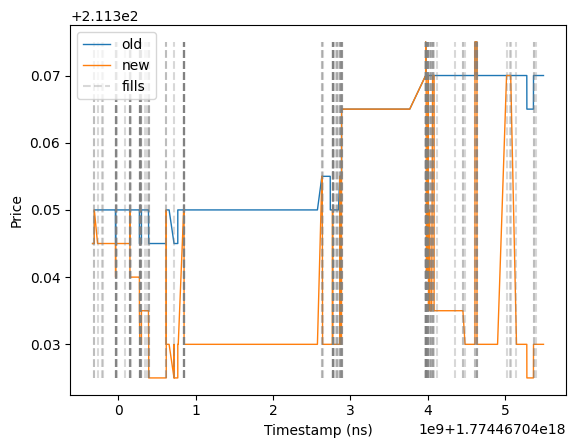

Total Filled: 5000 of 5000


In [11]:
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
LIMIT_PX = old_df.filter(pl.col("ts_event_nano") == TS_NANO)["bid_px_03"][0]
PARENT_QTY = 5000
SIDE="SELL"
MAX_SIZE = 100
OBI_THRESHOLD = 0.4
HORIZON = 3 * 60 * 60 * 10e9 # 3hr in ns

results, new_df, candidates = obi_adaptive_filler(old_df, SIDE, PARENT_QTY, MAX_SIZE, OBI_THRESHOLD, TS_NANO, HORIZON, sim=sim)

new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results[0]['executed_at_idx']-10
i_end = results[-1]['executed_at_idx']+10
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines([r["executed_at_ns"] for r in results], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()


print(f"Total Filled: {sum(r["total_filled"] for r in results)} of {PARENT_QTY}")

In [12]:
candidates

ts_event_nano,instrument_id,bid_px_00,ask_px_00,bid_sz_00,ask_sz_00,bid_px_01,ask_px_01,bid_sz_01,ask_sz_01,bid_px_02,ask_px_02,bid_sz_02,ask_sz_02,bid_px_03,ask_px_03,bid_sz_03,ask_sz_03,bid_px_04,ask_px_04,bid_sz_04,ask_sz_04,bid_px_05,ask_px_05,bid_sz_05,ask_sz_05,bid_px_06,ask_px_06,bid_sz_06,ask_sz_06,bid_px_07,ask_px_07,bid_sz_07,ask_sz_07,bid_px_08,ask_px_08,bid_sz_08,ask_sz_08,bid_px_09,ask_px_09,bid_sz_09,ask_sz_09,obi,order_size
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
1774467045407483542,853,211.28,211.38,357.0,212.0,211.27,211.39,532.0,259.0,211.26,211.4,100.0,251.0,211.25,211.41,100.0,375.0,211.24,211.42,100.0,516.0,211.23,211.43,100.0,524.0,211.22,211.44,100.0,231.0,211.21,211.45,100.0,334.0,211.2,211.46,100.0,226.0,211.19,211.47,100.0,434.0,0.254833,25
1774467045407896860,853,211.28,211.38,357.0,212.0,211.27,211.39,532.0,259.0,211.26,211.4,100.0,251.0,211.25,211.41,100.0,275.0,211.24,211.42,100.0,516.0,211.23,211.43,100.0,524.0,211.22,211.44,100.0,231.0,211.21,211.45,100.0,334.0,211.2,211.46,100.0,226.0,211.19,211.47,100.0,434.0,0.254833,25
1774467045408218623,853,211.28,211.38,357.0,212.0,211.27,211.39,532.0,259.0,211.26,211.4,100.0,251.0,211.25,211.41,100.0,275.0,211.24,211.42,100.0,416.0,211.23,211.43,100.0,524.0,211.22,211.44,100.0,231.0,211.21,211.45,100.0,334.0,211.2,211.46,100.0,226.0,211.19,211.47,100.0,434.0,0.254833,25
1774467045408222648,853,211.28,211.38,357.0,212.0,211.27,211.39,532.0,259.0,211.26,211.4,100.0,251.0,211.25,211.41,100.0,275.0,211.24,211.42,100.0,416.0,211.23,211.43,100.0,524.0,211.22,211.44,100.0,231.0,211.21,211.45,100.0,334.0,211.2,211.46,100.0,226.0,211.19,211.47,100.0,434.0,0.254833,25
1774467045408252346,853,211.28,211.38,357.0,212.0,211.27,211.39,532.0,259.0,211.26,211.4,100.0,251.0,211.25,211.41,100.0,275.0,211.24,211.42,100.0,416.0,211.23,211.43,100.0,524.0,211.22,211.44,100.0,331.0,211.21,211.45,100.0,334.0,211.2,211.46,100.0,226.0,211.19,211.47,100.0,434.0,0.254833,25
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1774555199901307764,853,207.53,207.55,12.0,419.0,207.52,207.56,12678.0,20.0,207.5,207.58,3229.0,447.0,207.49,207.59,2500.0,349.0,207.48,207.6,63.0,376.0,207.47,207.61,4000.0,100.0,207.46,207.62,4590.0,70.0,207.45,207.63,3801.0,5354.0,207.44,207.64,5733.0,300.0,207.43,207.65,3600.0,1873.0,-0.944316,94
1774555199901317486,853,207.53,207.55,12.0,419.0,207.52,207.56,12678.0,4.0,207.5,207.58,3229.0,447.0,207.49,207.59,2500.0,349.0,207.48,207.6,63.0,376.0,207.47,207.61,4000.0,100.0,207.46,207.62,4590.0,70.0,207.45,207.63,3801.0,5354.0,207.44,207.64,5733.0,300.0,207.43,207.65,3600.0,1873.0,-0.944316,94
1774555199972702880,853,207.53,207.55,256.0,175.0,207.52,207.56,16967.0,1.0,207.5,207.58,3229.0,447.0,207.49,207.59,2767.0,348.0,207.48,207.6,63.0,376.0,207.47,207.61,4000.0,100.0,207.46,207.62,4590.0,70.0,207.45,207.63,3801.0,5354.0,207.44,207.64,5733.0,300.0,207.43,207.65,3600.0,1873.0,0.187935,18


In [13]:
new_df.filter(pl.any_horizontal(pl.all().is_nan()))

ts_event_nano,instrument_id,bid_px_00,ask_px_00,bid_sz_00,ask_sz_00,bid_px_01,ask_px_01,bid_sz_01,ask_sz_01,bid_px_02,ask_px_02,bid_sz_02,ask_sz_02,bid_px_03,ask_px_03,bid_sz_03,ask_sz_03,bid_px_04,ask_px_04,bid_sz_04,ask_sz_04,bid_px_05,ask_px_05,bid_sz_05,ask_sz_05,bid_px_06,ask_px_06,bid_sz_06,ask_sz_06,bid_px_07,ask_px_07,bid_sz_07,ask_sz_07,bid_px_08,ask_px_08,bid_sz_08,ask_sz_08,bid_px_09,ask_px_09,bid_sz_09,ask_sz_09,mid
i64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
